<h1>3.32</h1>

In [1]:
import numpy as np

def approx_integral(f, a, b, n, rule):
    '''
    f: function to integrate
    a: lower bound
    b: upper bound
    n: number of subintervals
    rectangle: left/right/midpoint
    
    1. width of the interval
    2. apply the method:
        left: apply function value at the start of each subinterval
        right: apply function value at the end of each subinterval
        midpoint: apply function value at the midpoint of each subinterval
    3. add the area of each rectangle f(x) * width (not use loop)
    '''
    
    width = (b-a)/n # width of each subinterval
    
    if rule == "left":
        x = np.linspace(a, b-width, n)
    elif rule == "right":
        x = np.linspace(a+width, b, n)
    elif rule == "midpoint":
        x = np.linspace((a+width)/2, (b-width)/2, n)
        
    
    total_area = np.sum(f(x) * width)
    
    return total_area


In [2]:
import scipy as sp
f = lambda x: x**2

F = sp.integrate.quad(f, 0, 1)
print(F[0])

F = lambda x: (1/3) * x**3

print(F(1) - F(0))


0.3333333333333333
0.3333333333333333


<h1>3.36</h1>

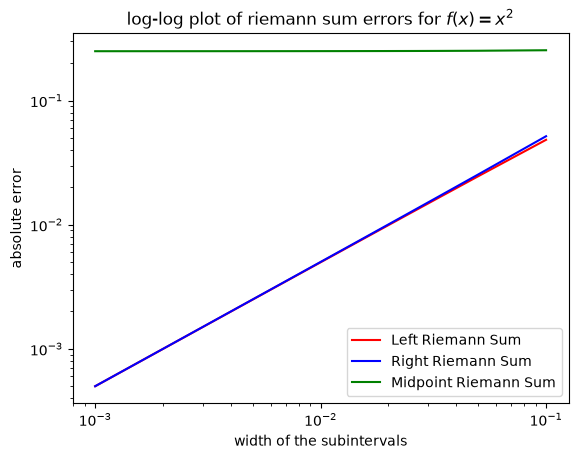

In [3]:
f = lambda x: x**2
F = lambda x: (1/3) * x**3

a = 0
b = 1 
n = np.arange(10, 1010, 10)
rule = ["left", "right", "midpoint"]

exact = F(b) - F(a)


left_error = []
right_error = []
midpoint_error = []


for i in n:
    left_approx = approx_integral(f, a, b, i, 'left')
    right_approx = approx_integral(f, a, b, i, "right")
    midpoint_approx = approx_integral(f, a, b, i, 'midpoint')
    
    left_error.append(np.abs(left_approx - exact))
    right_error.append(np.abs(right_approx - exact))
    midpoint_error.append(np.abs(midpoint_approx - exact))

length = [(b-a)/i for i in n]


import matplotlib.pyplot as plt

plt.loglog(length, left_error, "r", label = "Left Riemann Sum")
plt.loglog(length, right_error, "b", label = "Right Riemann Sum")
plt.loglog(length, midpoint_error, "g", label = "Midpoint Riemann Sum")

plt.xlabel("width of the subintervals")
plt.ylabel("absolute error")
plt.title("log-log plot of riemann sum errors for $f(x) = x^2$")
plt.legend()
plt.show()


<h1>3.39</h1>

333.3333333333333 333.35000000000014


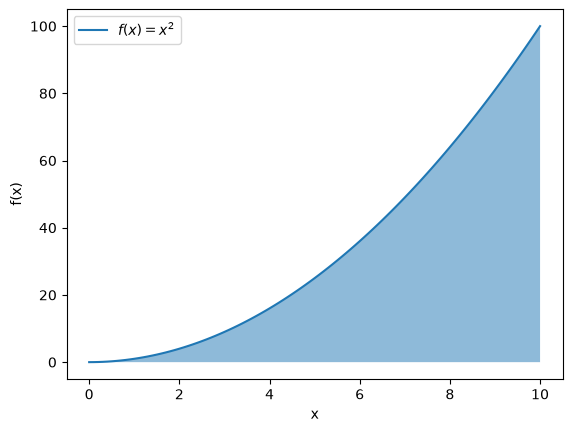

In [4]:
def trapezoidal(f, a, b, n):
    '''
    f: function
    a: lower bound
    b: upper bound
    n: number of subinterval
    '''
    
    width = (b-a)/n # width for each trapezoid
    
    x = np.linspace(a, b, n+1) # x values
    
    y = f(x) # function values at x
    
    area = (y[0] + 2*np.sum(y[1:-1]) + y[-1]) * width / 2 # area of each trapezoid, first and last function values (y) are only used once
    
    return area 

f = lambda x: x**2
F = lambda x: (1/3) * x**3

a = 0
b = 10
n = 100

exact = F(b)-F(a)
approx = trapezoidal(f, a, b, n)

print(exact, approx)

x = np.linspace(a, b, n+1)
    
y = f(x)

plt.plot(x, y, label='$f(x) = x^2$')
plt.fill_between(x, y, alpha = 0.5)

plt.xlabel('x')
plt.ylabel('f(x)')

plt.legend()
plt.show()

<h1>3.40</h1>

In [5]:
import pandas as pd

f = lambda x: np.sin(x)
F = lambda x: -np.cos(x)

a, b = 0, np.pi
n_values = np.arange(10, 110, 10)
exact = F(b) - F(a)

# Relative error of the trapezoidal rule for each n.
relative_errors = []
for n in n_values:
    approximation = trapezoidal(f, a, b, n)
    relative_errors.append(abs(approximation - exact) / exact)

# Double the number of subintervals and repeat.
new_n = n_values * 2
new_relative_errors = []
for n in new_n:
    approximation = trapezoidal(f, a, b, n)
    new_relative_errors.append(abs(approximation - exact) / exact)

result = pd.DataFrame({
    "n": n_values,
    "delta_x": (b - a) / n_values,
    "relative_error": relative_errors,
    "2n": new_n,
    "delta_x / 2": (b - a) / new_n,
    "error with 2n": new_relative_errors,
})
print(result)


     n   delta_x  relative_error   2n  delta_x / 2  error with 2n
0   10  0.314159        0.008238   20     0.157080       0.002057
1   20  0.157080        0.002057   40     0.078540       0.000514
2   30  0.104720        0.000914   60     0.052360       0.000228
3   40  0.078540        0.000514   80     0.039270       0.000129
4   50  0.062832        0.000329  100     0.031416       0.000082
5   60  0.052360        0.000228  120     0.026180       0.000057
6   70  0.044880        0.000168  140     0.022440       0.000042
7   80  0.039270        0.000129  160     0.019635       0.000032
8   90  0.034907        0.000102  180     0.017453       0.000025
9  100  0.031416        0.000082  200     0.015708       0.000021
